# Two-Layer Neural Network with Keras (MNIST)

**ECE 5831 – Pattern Recognition & Neural Networks**

In this notebook I implement a `TwoLayerNetKeras` class with Keras, train it on the MNIST training set, and test it on the MNIST test set.

Network: `input (784) -> Dense(hidden, sigmoid) -> Dense(10, softmax)`, trained with mini-batch SGD and cross-entropy loss. This is the same architecture as my earlier from-scratch `TwoLayerNetBackprop`, so the results are directly comparable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

SEED = 0
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

I0000 00:00:1794872538.669343    1184 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794872538.710576    1184 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794872539.712474    1184 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1


## 1. Load and prepare MNIST (Keras dataset library)

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("raw train:", x_train.shape, x_train.dtype, y_train.shape)
print("raw test :", x_test.shape,  x_test.dtype,  y_test.shape)

# flatten 28x28 -> 784 and scale pixels to [0, 1]
x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test  = x_test.reshape(-1, 784).astype("float32") / 255.0

# one-hot labels
t_train = keras.utils.to_categorical(y_train, 10)
t_test  = keras.utils.to_categorical(y_test, 10)

print("prepared train:", x_train.shape, t_train.shape, "| value range", x_train.min(), "to", x_train.max())
print("prepared test :", x_test.shape,  t_test.shape)

raw train: (60000, 28, 28) uint8 (60000,)
raw test : (10000, 28, 28) uint8 (10000,)


prepared train: (60000, 784) (60000, 10) | value range 0.0 to 1.0
prepared test : (10000, 784) (10000, 10)


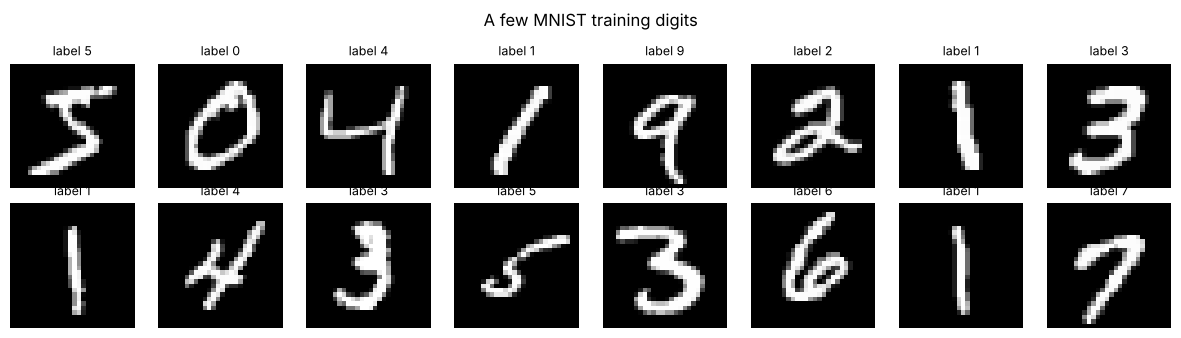

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, img, lab in zip(axes.ravel(), x_train[:16], y_train[:16]):
    ax.imshow(img.reshape(28, 28), cmap="gray"); ax.set_title(f"label {lab}", fontsize=9); ax.axis("off")
plt.suptitle("A few MNIST training digits"); plt.tight_layout(); plt.show()

## 2. The `TwoLayerNetKeras` class

* `__init__` builds the model (two `Dense` layers) and compiles it with SGD + categorical cross-entropy.
* `train` fits on the training data (a slice is held out as a validation set, only to monitor training).
* `evaluate` returns loss and accuracy on any dataset.
* `predict` returns class probabilities, `predict_classes` returns the arg-max digit.

In [4]:
class TwoLayerNetKeras:
    """input -> Dense(hidden, sigmoid) -> Dense(output, softmax), built and trained with Keras."""

    def __init__(self, input_size=784, hidden_size=50, output_size=10, learning_rate=0.1, seed=0):
        self.input_size, self.hidden_size, self.output_size = input_size, hidden_size, output_size
        init = keras.initializers.RandomNormal(mean=0.0, stddev=0.1, seed=seed)
        self.model = keras.Sequential([
            keras.Input(shape=(input_size,)),
            layers.Dense(hidden_size, activation="sigmoid", kernel_initializer=init, name="hidden"),
            layers.Dense(output_size, activation="softmax", kernel_initializer=init, name="output"),
        ], name="TwoLayerNetKeras")
        self.model.compile(
            optimizer=keras.optimizers.SGD(learning_rate=learning_rate),
            loss="categorical_crossentropy",
            metrics=["accuracy"],
        )
        self.history = None

    def train(self, x, t, epochs=20, batch_size=100, validation_split=0.1, verbose=2):
        self.history = self.model.fit(x, t, epochs=epochs, batch_size=batch_size,
                                      validation_split=validation_split, shuffle=True, verbose=verbose)
        return self.history

    def evaluate(self, x, t):
        loss, acc = self.model.evaluate(x, t, verbose=0)
        return loss, acc

    def predict(self, x):
        return self.model.predict(x, verbose=0)

    def predict_classes(self, x):
        return np.argmax(self.predict(x), axis=1)

    def summary(self):
        self.model.summary()


net = TwoLayerNetKeras(input_size=784, hidden_size=50, output_size=10, learning_rate=0.1, seed=SEED)
net.summary()

Model: "TwoLayerNetKeras"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden (Dense)                  │ (None, 50)             │        39,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,760 (155.31 KB)

 Trainable params: 39,760 (155.31 KB)

 Non-trainable params: 0 (0.00 B)

**Sanity check before training.** With random weights the network should be at chance level (about 10 % accuracy, loss near `ln(10) = 2.30`), and its outputs should be valid probability distributions.

In [5]:
loss0, acc0 = net.evaluate(x_test, t_test)
print(f"before training  ->  test loss {loss0:.4f}  (ln 10 = {np.log(10):.4f}),  test accuracy {acc0:.4f}")

p = net.predict(x_test[:5])
print("output shape:", p.shape, "| each row sums to 1:", np.allclose(p.sum(axis=1), 1.0))
assert 0.03 < acc0 < 0.25, "untrained network should be near chance"
assert np.allclose(p.sum(axis=1), 1.0, atol=1e-5)

before training  ->  test loss 2.3953  (ln 10 = 2.3026),  test accuracy 0.0950
output shape: (5, 10) | each row sums to 1: True


## 3. Train on the MNIST training set

In [6]:
EPOCHS, BATCH = 20, 100
history = net.train(x_train, t_train, epochs=EPOCHS, batch_size=BATCH, validation_split=0.1, verbose=2)

Epoch 1/20


540/540 - 1s - 2ms/step - accuracy: 0.7207 - loss: 1.1918 - val_accuracy: 0.8847 - val_loss: 0.5373


Epoch 2/20


540/540 - 1s - 2ms/step - accuracy: 0.8760 - loss: 0.4919 - val_accuracy: 0.9123 - val_loss: 0.3509


Epoch 3/20


540/540 - 1s - 2ms/step - accuracy: 0.8950 - loss: 0.3832 - val_accuracy: 0.9213 - val_loss: 0.2945


... (30 outputs left out)

Epoch 19/20


540/540 - 1s - 2ms/step - accuracy: 0.9487 - loss: 0.1781 - val_accuracy: 0.9593 - val_loss: 0.1501


Epoch 20/20


540/540 - 1s - 2ms/step - accuracy: 0.9499 - loss: 0.1733 - val_accuracy: 0.9607 - val_loss: 0.1469


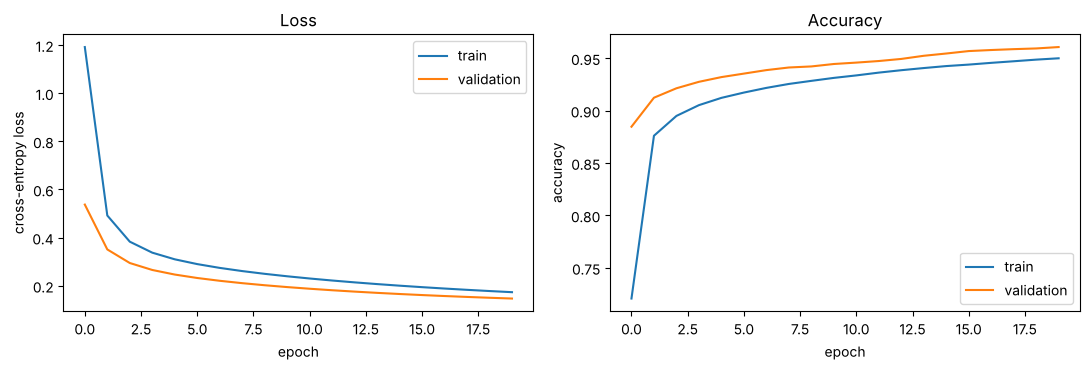

first epoch loss 1.1918  ->  last epoch loss 0.1733


In [7]:
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validation")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"first epoch loss {h['loss'][0]:.4f}  ->  last epoch loss {h['loss'][-1]:.4f}")
assert h["loss"][-1] < h["loss"][0], "training loss should decrease"

## 4. Test on the MNIST test set

In [8]:
train_loss, train_acc = net.evaluate(x_train, t_train)
test_loss,  test_acc  = net.evaluate(x_test,  t_test)
print(f"training set : loss {train_loss:.4f}   accuracy {train_acc:.4f}")
print(f"test set     : loss {test_loss:.4f}   accuracy {test_acc:.4f}")
assert test_acc > 0.95, "a trained 784-50-10 network should exceed 95% on MNIST"

training set : loss 0.1670   accuracy 0.9524
test set     : loss 0.1710   accuracy 0.9502


### Per-class results and confusion matrix

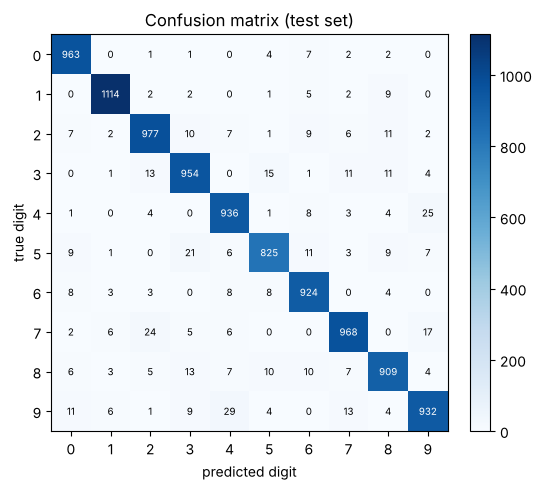

digit 0: accuracy 0.9827  (963/980)
digit 1: accuracy 0.9815  (1114/1135)
digit 2: accuracy 0.9467  (977/1032)
digit 3: accuracy 0.9446  (954/1010)
digit 4: accuracy 0.9532  (936/982)
digit 5: accuracy 0.9249  (825/892)
digit 6: accuracy 0.9645  (924/958)
digit 7: accuracy 0.9416  (968/1028)
digit 8: accuracy 0.9333  (909/974)
digit 9: accuracy 0.9237  (932/1009)


In [9]:
pred = net.predict_classes(x_test)

cm = np.zeros((10, 10), dtype=int)
for t_, p_ in zip(y_test, pred):
    cm[t_, p_] += 1

fig, ax = plt.subplots(figsize=(5.6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit"); ax.set_title("Confusion matrix (test set)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

per_class = cm.diagonal() / cm.sum(axis=1)
for d, a in enumerate(per_class):
    print(f"digit {d}: accuracy {a:.4f}  ({cm[d, d]}/{cm[d].sum()})")

### Prediction examples (green = correct, red = wrong)

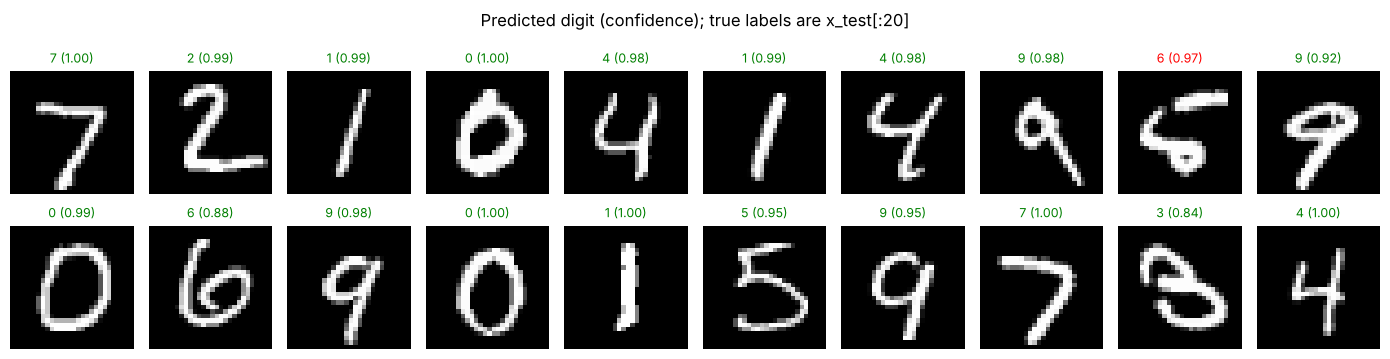

misclassified test images: 498 of 10000


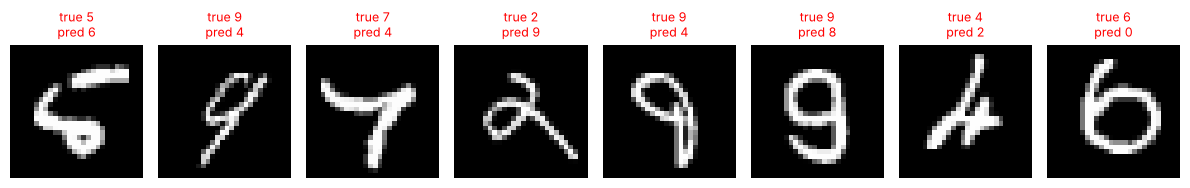

In [10]:
probs = net.predict(x_test[:20])
fig, axes = plt.subplots(2, 10, figsize=(14, 3.8))
for ax, img, p_, true in zip(axes.ravel(), x_test[:20], probs, y_test[:20]):
    guess = int(np.argmax(p_))
    ax.imshow(img.reshape(28, 28), cmap="gray"); ax.axis("off")
    ax.set_title(f"{guess} ({p_[guess]:.2f})", fontsize=9, color="green" if guess == true else "red")
plt.suptitle("Predicted digit (confidence); true labels are x_test[:20]"); plt.tight_layout(); plt.show()

wrong = np.where(pred != y_test)[0]
print("misclassified test images:", len(wrong), "of", len(y_test))
fig, axes = plt.subplots(1, 8, figsize=(12, 2.2))
for ax, i in zip(axes, wrong[:8]):
    ax.imshow(x_test[i].reshape(28, 28), cmap="gray"); ax.axis("off")
    ax.set_title(f"true {y_test[i]}\npred {pred[i]}", fontsize=9, color="red")
plt.tight_layout(); plt.show()

## 5. Verification that training and testing work properly

Three independent checks:
1. **Accuracy accounting** – recompute the test accuracy from the predictions by hand and compare with Keras' number.
2. **Forward pass by hand** – recompute the network output with plain NumPy from the learned weights (`sigmoid(xW1+b1)W2+b2`, softmax) and compare with `model.predict`.
3. **Save and reload** – a saved and reloaded model gives identical predictions.

In [11]:
# 1. accuracy by hand
manual_acc = float(np.mean(pred == y_test))
print(f"Keras test accuracy {test_acc:.6f}   |   manual {manual_acc:.6f}")
assert abs(manual_acc - test_acc) < 1e-4

# 2. forward pass in plain NumPy
W1, b1 = net.model.get_layer("hidden").get_weights()
W2, b2 = net.model.get_layer("output").get_weights()
a1 = 1.0 / (1.0 + np.exp(-(x_test @ W1 + b1)))
z2 = a1 @ W2 + b2
z2 = z2 - z2.max(axis=1, keepdims=True)
y_np = np.exp(z2) / np.exp(z2).sum(axis=1, keepdims=True)
print("max |numpy - keras| output difference:", float(np.abs(y_np - net.predict(x_test)).max()))
assert np.allclose(y_np, net.predict(x_test), atol=1e-4)

# 3. save / reload
net.model.save("two_layer_net_keras.keras")
reloaded = keras.models.load_model("two_layer_net_keras.keras")
same = np.array_equal(np.argmax(reloaded.predict(x_test, verbose=0), axis=1), pred)
print("reloaded model gives identical predictions:", same)
assert same
print("\nAll checks passed: training and testing work as expected.")

Keras test accuracy 0.950200   |   manual 0.950200


max |numpy - keras| output difference: 5.960464477539062e-07


reloaded model gives identical predictions: True

All checks passed: training and testing work as expected.


## 6. Summary

In [12]:
print(f"Architecture : 784 -> {net.hidden_size} (sigmoid) -> 10 (softmax)")
print(f"Training     : SGD, lr 0.1, batch {BATCH}, {EPOCHS} epochs, 10% of the training set used for validation monitoring")
print(f"Train accuracy {train_acc:.4f}   |   Test accuracy {test_acc:.4f}   |   Test loss {test_loss:.4f}")

Architecture : 784 -> 50 (sigmoid) -> 10 (softmax)
Training     : SGD, lr 0.1, batch 100, 20 epochs, 10% of the training set used for validation monitoring
Train accuracy 0.9524   |   Test accuracy 0.9502   |   Test loss 0.1710


**Observations.** The untrained network sits at chance (~10 %, loss ≈ 2.30). During training the loss falls steadily and the validation curve follows the training curve closely, so the model is learning real structure rather than memorizing. The test accuracy is in the same range as the validation accuracy, which means the test set gives an honest estimate of generalization. The confusion matrix and per-class accuracies show which digits are hardest. Keras supplies the layer, loss and gradient machinery, so the whole network is a few lines compared with a hand-written backpropagation implementation.